# Long-term evolution of the field

A heating-dominated building slowly cools the ground around its field. This notebook simulates
the office building of `demo_project.py` over 50 years and plots, for each year, the coldest hour,
the warmest hour and the yearly mean of the entering fluid temperature. It is the notebook version
of `field_ageing.py`.

Run it from the `examples` folder, with the executable and a licence (see
[Installation](../docs/install.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()

## Simulation, cut into years

In [2]:
years = 50

p = make_project()
p.simulation_duration = years
eft = p.simulate().eft.reshape(years, 8760)
coldest, mean, warmest = eft.min(axis=1), eft.mean(axis=1), eft.max(axis=1)

for year in (1, 5, 10, 25, 50):
    print(f"year {year:2d}  ->  EFT from {coldest[year - 1]:5.2f} to {warmest[year - 1]:5.2f} °C")

year  1  ->  EFT from  3.45 to 16.39 °C
year  5  ->  EFT from  1.93 to 14.89 °C
year 10  ->  EFT from  1.29 to 14.26 °C
year 25  ->  EFT from  0.59 to 13.53 °C
year 50  ->  EFT from  0.23 to 13.15 °C


## Figure

The three curves drop quickly during the first decade and more slowly afterwards.

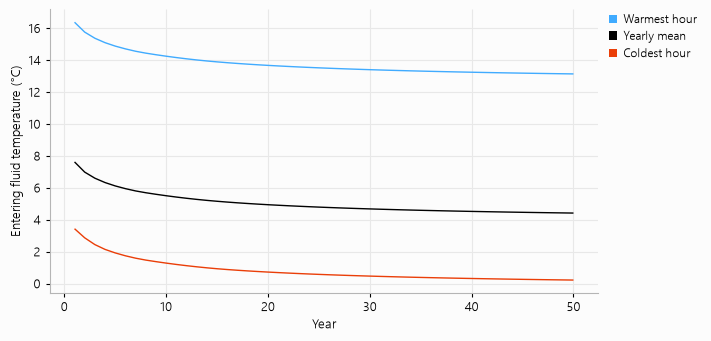

In [3]:
fig, ax = ghe.figure(width=7.0)
year = np.arange(1, years + 1)
ax.plot(year, warmest, color=ghe.COOLING)
ax.plot(year, mean, color=ghe.BLACK)
ax.plot(year, coldest, color=ghe.HEATING)
ghe.legend(ax, [(ghe.COOLING, "Warmest hour"), (ghe.BLACK, "Yearly mean"),
                (ghe.HEATING, "Coldest hour")])
ghe.axis_titles(ax, "Year", "Entering fluid temperature (°C)")
plt.show()